# 02 · Model Training and Comparison
**Project:** Early Disease Prediction Using Machine Learning on Health Data

This notebook trains three models and compares them fairly:

| Model | Why it is here |
| --- | --- |
| **Logistic Regression** | Simple, fast and easy to explain. A good first baseline. |
| **Random Forest** | Many decision trees voting together. Can capture non-linear effects. |
| **XGBoost** | Boosted trees. Often the strongest model on table data. |

**How we keep the test fair**
- The data is split once into **80% train / 20% test**, stratified so both parts keep the same class ratio and the same original / synthetic mix.
- All tuning uses **5-fold cross-validation on the training part only**. The test part is used once, at the end.
- Scaling lives **inside the pipeline**, so it is learned from training folds only (no data leakage).
- The final model is chosen by **cross-validated ROC-AUC**, not by test score.
- Class imbalance is handled with class weights, never by copying test rows.

> **Disclaimer:** this is a student research project on partly synthetic data. It must **not** be used for clinical diagnosis or medical decisions without supervision by qualified medical professionals.

In [1]:
import sys, warnings
from pathlib import Path

# Find the project folder whether the notebook is opened from /notebooks or from the project root
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as C, data_utils as D, evaluate as E, viz

%matplotlib inline
viz.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
from sklearn.model_selection import StratifiedKFold, learning_curve
from src.train import run_training

## 1 · The split

In [2]:
df = D.clean_data(D.load_data())
train_df, test_df = D.split_data(df)
parts = {"Original rows": df[D.source_of(df) == "original"], "Synthetic rows": df[D.source_of(df) == "synthetic"],
         "Full data": df, "Train (80%)": train_df, "Test (20%)": test_df}
pd.DataFrame({k: {"rows": len(v), "disease share": v[C.TARGET].mean()} for k, v in parts.items()}).T

,rows,disease share
Original rows,500.0,0.394
Synthetic rows,4500.0,0.512
Full data,5000.0,0.500
Train (80%),4000.0,0.500
Test (20%),1000.0,0.500


Train and test have the same share of disease cases, so no part of the data is easier than the other.

## 2 · Tune and train all three models
`run_training()` does the following for each model: searches settings with 5-fold cross-validation (a full grid for Logistic Regression, 20 random draws for Random Forest and XGBoost), refits the best setting on the full training part, and scores it on the test part. It also saves the models, metrics and figures. This takes about two minutes.

In [3]:
out = run_training(save=True, verbose=True)
results, proba_test = out["results"], out["proba_test"]
best_name, threshold = out["best_name"], out["threshold"]
y_test = test_df[C.TARGET]

Train (4000, 6), test (1000, 6); disease share train 0.500, test 0.500


Logistic Regression  CV AUC 0.816 (+/- 0.014)  test AUC 0.822


Random Forest        CV AUC 0.806 (+/- 0.015)  test AUC 0.816


XGBoost              CV AUC 0.810 (+/- 0.014)  test AUC 0.815
Selected model: Logistic Regression


Saved models, metrics and figures (106.0 s)


## 3 · Results table
Cross-validation (CV) columns come from the training part. Test columns come from the untouched test part.

In [4]:
table = pd.read_csv(C.COMPARISON_PATH).set_index("model")
display(table[["cv_roc_auc", "cv_roc_auc_std", "cv_f1", "cv_recall", "test_roc_auc", "test_pr_auc",
               "test_accuracy", "test_precision", "test_recall", "test_f1", "test_brier"]])
print("Majority-class baseline accuracy on the test set:", round(out["metrics"]["baseline_majority_class"]["accuracy"], 3))

,cv_roc_auc,cv_roc_auc_std,cv_f1,cv_recall,test_roc_auc,test_pr_auc,test_accuracy,test_precision,test_recall,test_f1,test_brier
model,,,,,,,,,,,
Logistic Regression,0.816,0.014,0.736,0.736,0.822,0.796,0.749,0.749,0.750,0.749,0.172
Random Forest,0.806,0.015,0.734,0.742,0.816,0.784,0.743,0.741,0.748,0.744,0.178
XGBoost,0.810,0.014,0.736,0.741,0.815,0.788,0.734,0.734,0.734,0.734,0.175


Majority-class baseline accuracy on the test set: 0.5


In [5]:
pd.DataFrame({n: r["best_params"] for n, r in results.items()}).T.rename(columns=lambda c: c.replace("clf__", ""))

,C,n_estimators,min_samples_leaf,max_features,max_depth,subsample,reg_lambda,min_child_weight,learning_rate,colsample_bytree
Logistic Regression,0.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,500,3,sqrt,6,NaN,NaN,NaN,NaN,NaN
XGBoost,NaN,400.0,NaN,NaN,2.0,0.85,10.0,1.0,0.03,0.7


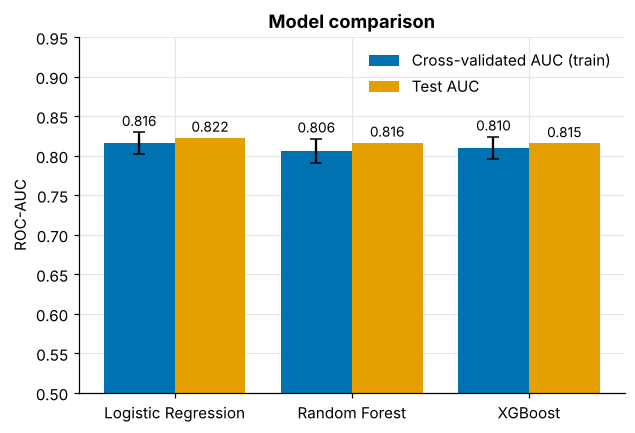

In [6]:
fig = E.plot_model_comparison(results)
plt.show()

All three models land close together (test AUC about 0.82). The gaps between them are smaller than the spread between cross-validation folds, so we should **not** claim that one model is truly better. Logistic Regression has the highest cross-validated AUC, so it is selected. It is also the simplest and easiest to explain, which matters for a health tool.

## 4 · ROC, precision-recall and calibration
- **ROC curve:** how well each model ranks sick patients above healthy ones (1.0 = perfect, 0.5 = guessing).
- **Precision-recall curve:** useful when we care most about finding the disease cases.
- **Calibration:** when a model says "70% risk", do about 70% of such patients really have the disease?

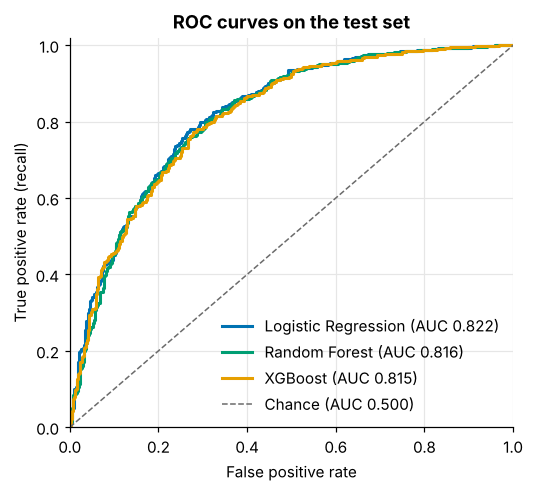

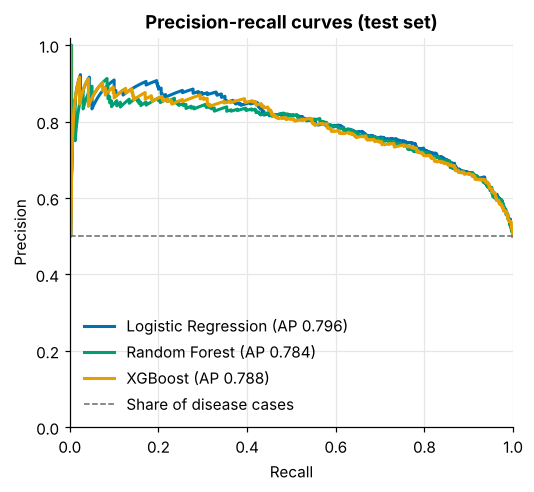

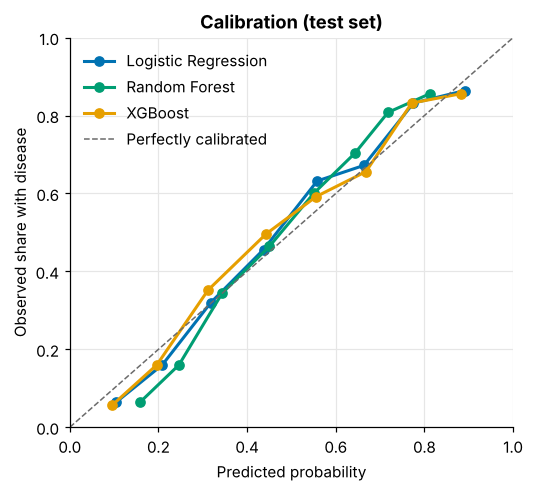

In [7]:
fig = E.plot_roc(y_test, proba_test); plt.show()
fig = E.plot_pr(y_test, proba_test); plt.show()
fig = E.plot_calibration(y_test, proba_test); plt.show()

## 5 · Confusion matrix and the screening threshold
For an **early-warning** tool, missing a sick patient (false negative) is worse than flagging a healthy one (false positive). So besides the usual 0.50 cut-off we pick a **screening threshold**: the highest cut-off that still catches at least 85% of sick patients. It is chosen from out-of-fold predictions on the **training** data only, so the test set stays untouched.

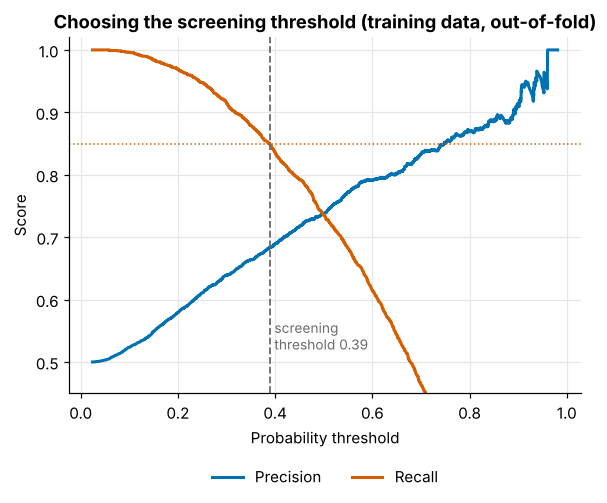

Screening threshold: 0.3884


In [8]:
fig = E.plot_threshold_tradeoff(D.xy(train_df)[1], out["oof_best"], threshold); plt.show()
print(f"Screening threshold: {threshold:.4f}")

,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
Default cut-off 0.50,0.500,0.749,0.749,0.750,0.748,0.749,0.822,0.796
Screening cut-off,0.388,0.742,0.698,0.854,0.630,0.768,0.822,0.796


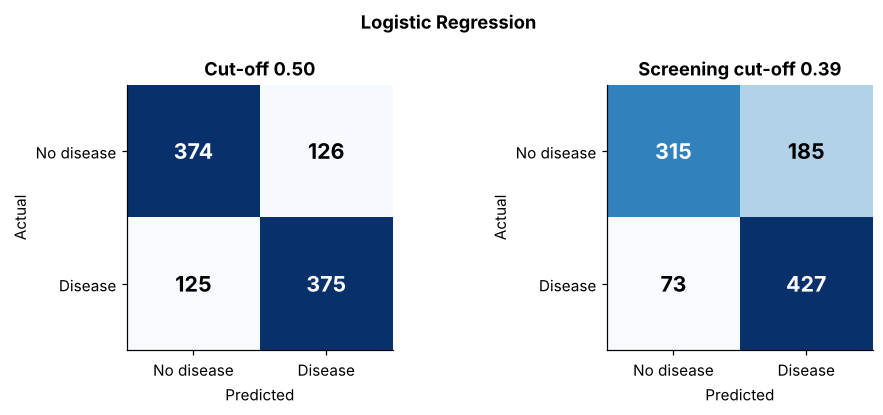

In [9]:
default = results[best_name]["test"]
screen = out["metrics"]["best_model_test_at_screening_threshold"]
cols = ["threshold", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc"]
display(pd.DataFrame({"Default cut-off 0.50": {c: default[c] for c in cols},
                      "Screening cut-off": {c: screen[c] for c in cols}}).T)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (m, t) in zip(axes, [(default, "Cut-off 0.50"), (screen, f"Screening cut-off {threshold:.2f}")]):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=14, fontweight="bold", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["No disease", "Disease"]); ax.set_yticks([0, 1], ["No disease", "Disease"])
    ax.set(title=t, xlabel="Predicted", ylabel="Actual")
fig.suptitle(best_name, fontweight="bold"); fig.tight_layout(); plt.show()

Moving to the screening cut-off raises recall to about 0.85 (fewer missed patients) and lowers specificity (more false alarms). That is the trade-off. A clinic would pick the cut-off together with doctors, not by a student's rule of thumb.

## 6 · Does more data help? (learning curve)

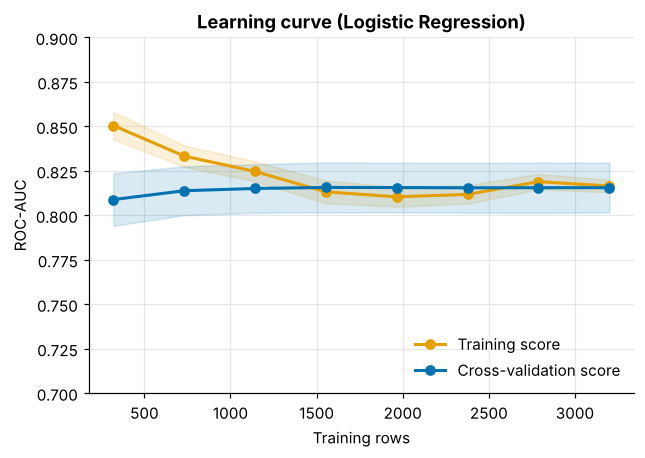

In [10]:
X_train, y_train = D.xy(train_df)
cv = StratifiedKFold(5, shuffle=True, random_state=C.RANDOM_STATE)
sizes, tr, va = learning_curve(out["models"][best_name], X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
                               cv=cv, scoring="roc_auc", n_jobs=-1)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for arr, lab, col in [(tr, "Training score", viz.ORANGE), (va, "Cross-validation score", viz.BLUE)]:
    ax.plot(sizes, arr.mean(1), marker="o", color=col, lw=2, label=lab)
    ax.fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), color=col, alpha=0.15)
ax.set(xlabel="Training rows", ylabel="ROC-AUC", title=f"Learning curve ({best_name})", ylim=(0.7, 0.9))
ax.legend(loc="lower right")
viz.save_fig(fig, "learning_curve"); plt.show()

The two lines meet and flatten out, so the model is not overfitting and more rows of the same kind would not help much. The ceiling is set by the features and the noise in the labels.

## 7 · Sanity check: original rows vs synthetic rows
Earlier (notebook 01) the 500 original rows showed no link between features and label. Here we measure what that means for modelling.

,ROC-AUC
setting,
"Logistic Regression, trained and cross-validated on the 500 original rows only",0.452
"Random Forest, trained and cross-validated on the 500 original rows only",0.496
"Logistic Regression (final model), test AUC on original test rows (n=100)",0.501
"Logistic Regression (final model), test AUC on synthetic test rows (n=900)",0.859


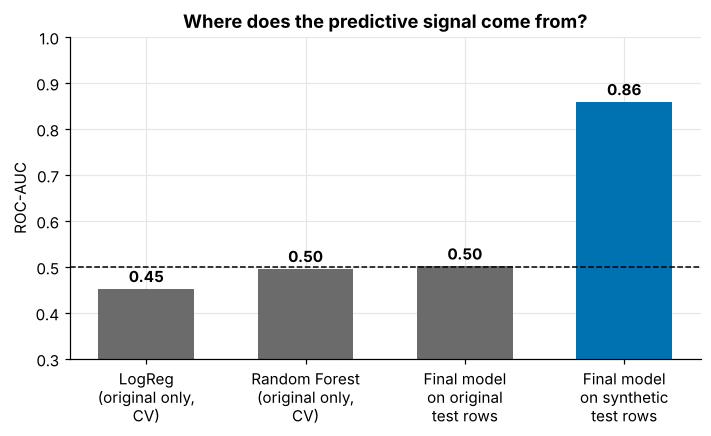

In [11]:
diag = out["metrics"]["diagnostics"]
orig_cv = diag["original_rows_only_cv"]
by_src = diag["best_model_test_auc_by_source"]
summary = pd.DataFrame({
    "setting": ["Logistic Regression, trained and cross-validated on the 500 original rows only",
                "Random Forest, trained and cross-validated on the 500 original rows only",
                f"{best_name} (final model), test AUC on original test rows (n={by_src['original']['n_test_rows']})",
                f"{best_name} (final model), test AUC on synthetic test rows (n={by_src['synthetic']['n_test_rows']})"],
    "ROC-AUC": [orig_cv["Logistic Regression"]["cv_roc_auc_mean"], orig_cv["Random Forest"]["cv_roc_auc_mean"],
                by_src["original"]["roc_auc"], by_src["synthetic"]["roc_auc"]]}).set_index("setting")
display(summary)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
labels = ["LogReg\n(original only,\nCV)", "Random Forest\n(original only,\nCV)", "Final model\non original\ntest rows", "Final model\non synthetic\ntest rows"]
bars = ax.bar(labels, summary["ROC-AUC"], color=[viz.GREY, viz.GREY, viz.GREY, viz.BLUE], width=0.6)
ax.axhline(0.5, color="black", ls="--", lw=1)
for b, v in zip(bars, summary["ROC-AUC"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontweight="bold")
ax.set(ylim=(0.3, 1.0), ylabel="ROC-AUC", title="Where does the predictive signal come from?")
viz.save_fig(fig, "auc_by_source"); plt.show()

## 8 · Key findings
1. **Final model: Logistic Regression** (C = 0.03). Cross-validated AUC 0.816 (± 0.014); test AUC **0.822** (95% bootstrap interval about 0.80 to 0.85); accuracy 0.75, recall 0.75, F1 0.75 at the 0.50 cut-off. The majority-class baseline gets 0.50 accuracy.
2. **The three models perform almost the same.** Test AUC is 0.822 (Logistic Regression), 0.816 (Random Forest) and 0.815 (XGBoost). A paired bootstrap in notebook 03 gives Logistic Regression only a tiny edge (0.006 to 0.007 AUC), so picking the simplest model is a sound choice.
3. **Screening cut-off 0.39** catches about 85% of sick patients in the test set, at the cost of a specificity of about 0.63.
4. **Important warning.** On the 500 original rows alone, models score a cross-validated AUC of about 0.45 to 0.50, which is chance. The final model scores about 0.50 on original test rows but about 0.86 on synthetic test rows. So the headline AUC of 0.82 is an average of "no signal" and "built-in signal". It shows that the pipeline works and can recover the relationships present in the data. It does **not** show that the model would predict disease in real patients.
5. **Next:** notebook 03 opens the model up with SHAP, permutation importance, subgroup checks and error analysis.